In [ ]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 39.8 MB/s eta 0:00:00


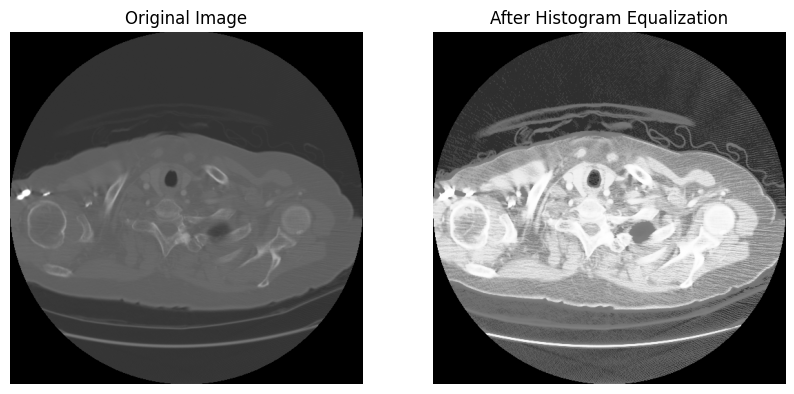

In [ ]:

import pydicom
import numpy as np
import cv2
import matplotlib.pyplot as plt

ds = pydicom.dcmread("/1-008.dcm")
image = ds.pixel_array.astype(np.float32)
image_8bit = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

he_img = cv2.equalizeHist(image_8bit)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(image_8bit, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(he_img, cmap='gray')
plt.title("After Histogram Equalization")
plt.axis('off')
plt.show()


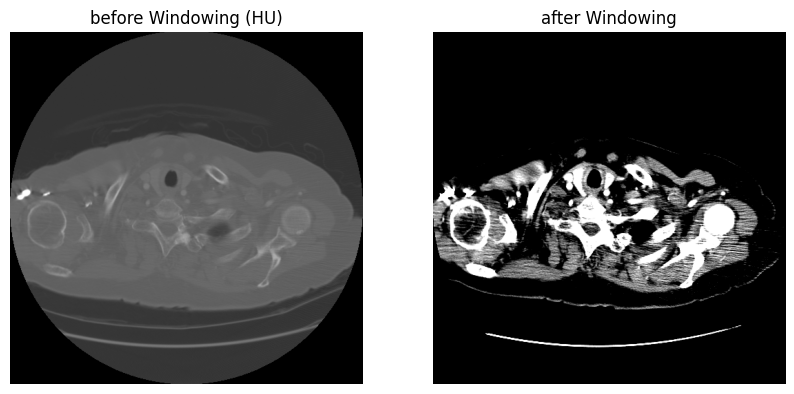

In [ ]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt

image_path = "/1-008.dcm"

ds = pydicom.dcmread(image_path)
image = ds.pixel_array.astype(np.float32)

slope = ds.RescaleSlope
intercept = ds.RescaleIntercept
image_hu = image * slope + intercept

def window_image(image_hu, window_center, window_width):
    min_hu = window_center - window_width / 2
    max_hu = window_center + window_width / 2
    windowed = np.clip(image_hu, min_hu, max_hu)
    windowed = ((windowed - min_hu) / (max_hu - min_hu) * 255).astype(np.uint8)
    return windowed

window_center = 50
window_width = 200
windowed_img = window_image(image_hu, window_center, window_width)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image_hu, cmap='gray')
plt.title("before Windowing (HU)")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(windowed_img, cmap='gray')
plt.title("after Windowing")
plt.axis('off')

plt.show()



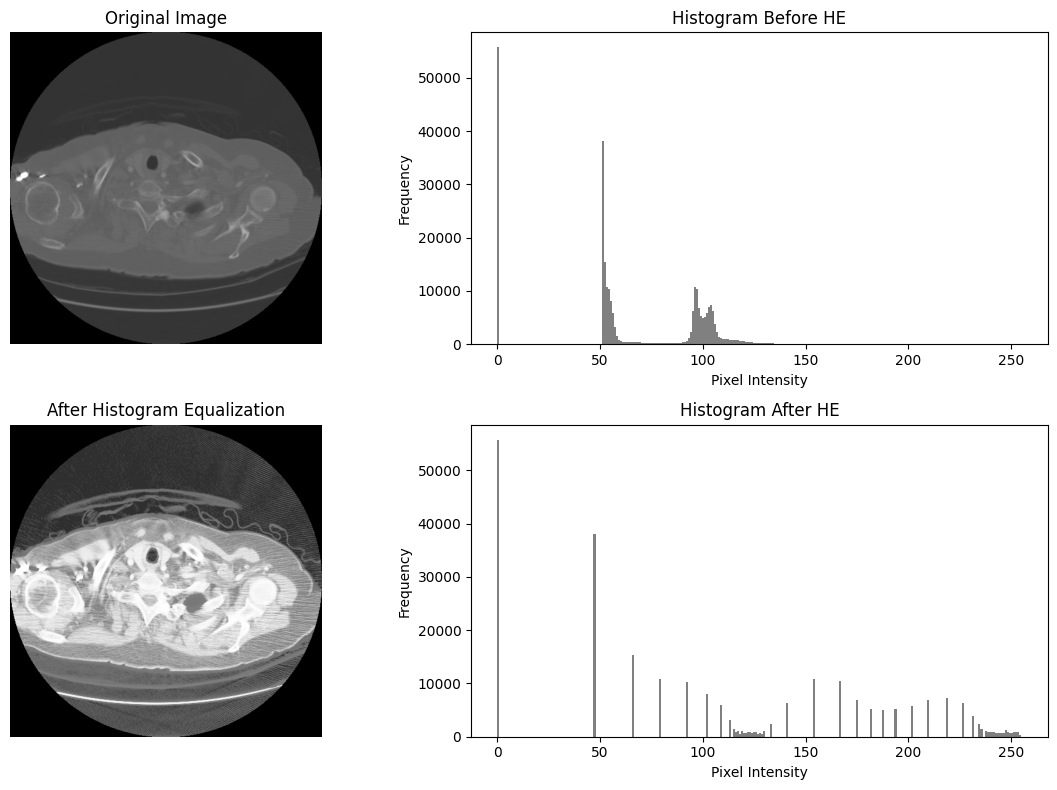

In [ ]:
import pydicom
import numpy as np
import cv2
import matplotlib.pyplot as plt


ds = pydicom.dcmread("/1-008.dcm")
image = ds.pixel_array.astype(np.float32)

image_8bit = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

he_img = cv2.equalizeHist(image_8bit)

plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
plt.imshow(image_8bit, cmap='gray')
plt.title("Original Image")
plt.axis('off')

# Histogram Before
plt.subplot(2,2,2)
plt.hist(image_8bit.ravel(), bins=256, color='gray')
plt.title("Histogram Before HE")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

# After HE Image
plt.subplot(2,2,3)
plt.imshow(he_img, cmap='gray')
plt.title("After Histogram Equalization")
plt.axis('off')

# Histogram After
plt.subplot(2,2,4)
plt.hist(he_img.ravel(), bins=256, color='gray')
plt.title("Histogram After HE")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


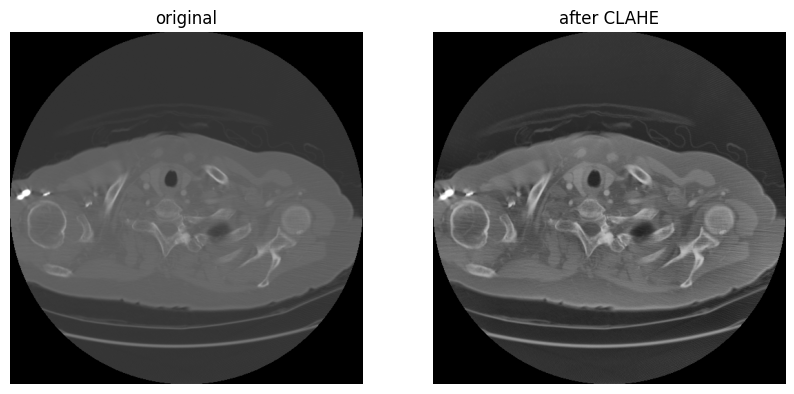

In [ ]:
import pydicom
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

image_path ="/1-008.dcm"
output_folder = "enhanced_images"
os.makedirs(output_folder, exist_ok=True)

ds = pydicom.dcmread(image_path)
image = ds.pixel_array.astype(np.float32)

image_8bit = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
enhanced_img = clahe.apply(image_8bit)


plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image_8bit, cmap='gray')
plt.title("original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(enhanced_img, cmap='gray')
plt.title("after CLAHE")
plt.axis('off')

plt.show()

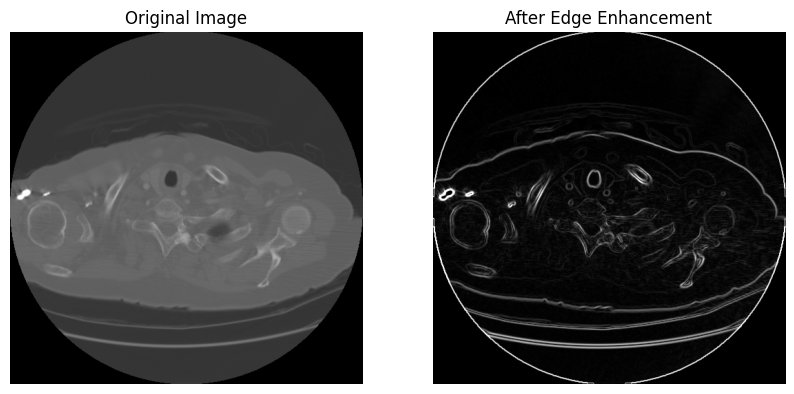

In [ ]:
import pydicom
import numpy as np
import cv2
import matplotlib.pyplot as plt

ds = pydicom.dcmread("/1-008.dcm")
image = ds.pixel_array.astype(np.float32)
image_8bit = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

sobelx = cv2.Sobel(image_8bit, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(image_8bit, cv2.CV_64F, 0, 1, ksize=3)
edge_img = np.sqrt(sobelx**2 + sobely**2)
edge_img = np.clip(edge_img, 0, 255).astype(np.uint8)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(image_8bit, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(edge_img, cmap='gray')
plt.title("After Edge Enhancement")
plt.axis('off')
plt.show()
